In [1]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="IProgress not found",
    category=UserWarning
)

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import optuna
import pacmap
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from pyDRMetrics.pyDRMetrics import DRMetrics

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

d:\Projetos Python\Mestrado\RBras\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def calcular_metricas_reducao(X, Z):

    dr_metrics = DRMetrics(X, Z)

    q_local = dr_metrics.Qlocal
    auc_qnn = dr_metrics.AUC

    return q_local, auc_qnn


def calcular_score_reducao(X, Z):

    q_local, auc_qnn = calcular_metricas_reducao(X, Z)

    score = 0.5 * q_local + 0.5 * auc_qnn

    return score, q_local, auc_qnn


def calcular_metricas_clustering(Z, labels):

    n_clusters = len(np.unique(labels))

    if n_clusters < 2 or n_clusters >= len(labels):
        raise ValueError("Número inválido de clusters.")

    sil_score = silhouette_score(Z, labels)

    ch_score = calinski_harabasz_score(Z, labels)

    ch_score_norm = ch_score / (ch_score + 1000)

    return sil_score, ch_score, ch_score_norm


def calcular_score_clustering(Z, labels):

    sil_score, ch_score, ch_score_norm = (
        calcular_metricas_clustering(Z, labels)
    )

    score = 0.5 * sil_score + 0.5 * ch_score_norm

    return score, sil_score, ch_score, ch_score_norm

## Importando as bases de dados

In [4]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import optuna
import pacmap
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from pyDRMetrics.pyDRMetrics import DRMetrics

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# Diretórios
# ============================================================

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

OPTUNA_DIR = RESULTS_DIR / "optuna"
EMBEDDINGS_DIR = RESULTS_DIR / "embeddings"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

for directory in [
    OPTUNA_DIR,
    EMBEDDINGS_DIR,
    METRICS_DIR,
    FIGURES_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# Carregamento da base
# ============================================================

df = pd.read_csv(
    DATA_DIR / "df_pca_50_mad5000.csv",
    index_col=0
)

clinical_final = pd.read_csv(
    DATA_DIR / "clinical_final.csv",
    index_col=0
)

# Mantém apenas a coluna de subtipo
clinical_final = clinical_final[["SUBTYPE"]]

# Alinha a tabela clínica à matriz de expressão
clinical_final = clinical_final.loc[df.index]

# Verificações
assert df.index.equals(clinical_final.index), (
    "Os índices da matriz de expressão e da tabela clínica não coincidem."
)

assert not df.isnull().values.any(), (
    "A matriz de expressão contém valores ausentes."
)

assert not clinical_final["SUBTYPE"].isnull().any(), (
    "A tabela clínica contém subtipos ausentes."
)

X_data = df.values
y_true = clinical_final["SUBTYPE"].values

print(f"Número de amostras: {X_data.shape[0]}")
print(f"Número de genes: {X_data.shape[1]}")
print(f"Número de subtipos clínicos: {clinical_final['SUBTYPE'].nunique()}")

print("\nDistribuição dos subtipos:")
print(clinical_final["SUBTYPE"].value_counts())

Número de amostras: 964
Número de genes: 50
Número de subtipos clínicos: 5

Distribuição dos subtipos:
SUBTYPE
BRCA_LumA      491
BRCA_LumB      192
BRCA_Basal     170
BRCA_Her2       76
BRCA_Normal     35
Name: count, dtype: int64


In [5]:
print("Embeddings:")
for arquivo in EMBEDDINGS_DIR.glob("*"):
    print(arquivo.name)

print("\nMetrics:")
for arquivo in METRICS_DIR.glob("*"):
    print(arquivo.name)

print("\nOptuna:")
for arquivo in OPTUNA_DIR.glob("*"):
    print(arquivo.name)

Embeddings:
embedding_decoupled_vst_mad_3000.csv
embedding_decoupled_vst_mad_3000_v2.csv
embedding_decoupled_vst_mad_5000.csv
embedding_joint_vst_mad_3000.csv
embedding_joint_vst_mad_3000_v2.csv
embedding_joint_vst_mad_5000.csv
gmm_decoupled_vst_mad_3000.pkl
gmm_decoupled_vst_mad_3000_v2.pkl
gmm_decoupled_vst_mad_5000.pkl
gmm_joint_vst_mad_3000.pkl
gmm_joint_vst_mad_3000_v2.pkl
gmm_joint_vst_mad_5000.pkl

Metrics:
comparison_vst_mad_3000.csv
comparison_vst_mad_3000.xlsx
comparison_vst_mad_3000_v2.csv
comparison_vst_mad_3000_v2.xlsx
hyperparameters_vst_mad_3000.csv
hyperparameters_vst_mad_3000_v2.csv

Optuna:
best_params_gmm_vst_mad_3000.json
best_params_gmm_vst_mad_3000_v2.json
best_params_gmm_vst_mad_5000.json
best_params_joint_vst_mad_3000.json
best_params_joint_vst_mad_3000_v2.json
best_params_joint_vst_mad_5000.json
best_params_pacmap_vst_mad_3000.json
best_params_pacmap_vst_mad_3000_v2.json
best_params_pacmap_vst_mad_5000.json
gmm_vst_mad_3000.db
gmm_vst_mad_3000_v2.db
gmm_vst_mad

## Embedding do PaCMAP e rótulos PAM50

In [6]:
df_embedding_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_5000.csv",
    index_col=0
)

df_embedding_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_5000.csv",
    index_col=0
)

# Embeddings desacoplados: 8 dimensões
Z_decoupled = df_embedding_decoupled[
    [f"PaCMAP_{i}" for i in range(1, 9)]
].to_numpy(dtype=float)

# Embeddings conjuntos: 7 dimensões
Z_joint = df_embedding_joint[
    [f"PaCMAP_{i}" for i in range(1, 8)]
].to_numpy(dtype=float)

# Rótulos GMM
labels_decoupled = df_embedding_decoupled[
    "Cluster"
].to_numpy()

labels_joint = df_embedding_joint[
    "Cluster"
].to_numpy()

# Subtipos PAM50
y_true = df_embedding_decoupled[
    "SUBTYPE"
].to_numpy()

print("Decoupled:", Z_decoupled.shape)
print("Joint:", Z_joint.shape)
print("Labels decoupled:", labels_decoupled.shape)
print("Labels joint:", labels_joint.shape)
print("PAM50:", y_true.shape)

Decoupled: (964, 8)
Joint: (964, 7)
Labels decoupled: (964,)
Labels joint: (964,)
PAM50: (964,)


## Agrupamentos por GMM

In [7]:
import joblib

gmm_decoupled = joblib.load(
    EMBEDDINGS_DIR / "gmm_decoupled_vst_mad_5000.pkl"
)

gmm_joint = joblib.load(
    EMBEDDINGS_DIR / "gmm_joint_vst_mad_5000.pkl"
)

print("Dimensões GMM desacoplado:", gmm_decoupled.means_.shape)
print("Dimensões GMM conjunto:", gmm_joint.means_.shape)

Dimensões GMM desacoplado: (4, 9)
Dimensões GMM conjunto: (4, 7)


## Cálculo das Métricas

In [8]:
# ============================================================
# Estratégia desacoplada
# ============================================================

score_dr_decoupled, q_local_decoupled, auc_qnn_decoupled = (
    calcular_score_reducao(
        X_data,
        Z_decoupled
    )
)

score_gmm_decoupled, sil_decoupled, ch_decoupled, ch_norm_decoupled = (
    calcular_score_clustering(
        Z_decoupled,
        labels_decoupled
    )
)

ari_decoupled = adjusted_rand_score(
    y_true,
    labels_decoupled
)


# ============================================================
# Estratégia conjunta
# ============================================================

score_dr_joint, q_local_joint, auc_qnn_joint = (
    calcular_score_reducao(
        X_data,
        Z_joint
    )
)

score_gmm_joint, sil_joint, ch_joint, ch_norm_joint = (
    calcular_score_clustering(
        Z_joint,
        labels_joint
    )
)

ari_joint = adjusted_rand_score(
    y_true,
    labels_joint
)

In [24]:
import joblib
import json
from types import SimpleNamespace

# ============================================================
# DECLARAÇÃO E CARREGAMENTO DOS BEST TRIALS
# ============================================================

# ------------------------------------------------------------
# 1. Best Trial - Abordagem Conjunta (Joint)
# ------------------------------------------------------------
file_study_joint_pkl = OPTUNA_DIR / "study_joint_vst_mad_5000.pkl"
json_joint_file = OPTUNA_DIR / "best_trial_info_joint_mad_5000.json"

if file_study_joint_pkl.exists():
    study_joint = joblib.load(file_study_joint_pkl)
    best_trial_joint = study_joint.best_trial
elif json_joint_file.exists():
    with open(json_joint_file, "r") as f:
        best_info_joint = json.load(f)
    # Cria uma estrutura equivalente ao objeto trial para manter o atributo .user_attrs
    best_trial_joint = SimpleNamespace(
        number=best_info_joint.get("number"),
        value=best_info_joint.get("value"),
        params=best_info_joint.get("params"),
        user_attrs=best_info_joint.get("user_attrs", {})
    )
else:
    raise FileNotFoundError("Nenhum arquivo do estudo Joint (pkl ou json) foi encontrado em OPTUNA_DIR.")


# ------------------------------------------------------------
# 2. Best Trial - Abordagem Desacoplada (Decoupled)
# ------------------------------------------------------------
file_pacmap_pkl = OPTUNA_DIR / "study_pacmap_vst_mad_5000.pkl"
file_gmm_pkl = OPTUNA_DIR / "study_gmm_vst_mad_5000.pkl"
json_decoupled_file = OPTUNA_DIR / "best_trial_info_decoupled_vst_mad_5000.json"

if file_pacmap_pkl.exists() and file_gmm_pkl.exists():
    study_pacmap = joblib.load(file_pacmap_pkl)
    study_gmm = joblib.load(file_gmm_pkl)
    
    # Atribuição dos dois trials individuais
    best_trial_pacmap = study_pacmap.best_trial
    best_trial_gmm = study_gmm.best_trial
    
    # Consolidação em uma única estrutura representativa para o modelo desacoplado
    best_trial_decoupled = SimpleNamespace(
        pacmap=best_trial_pacmap,
        gmm=best_trial_gmm,
        user_attrs={
            **best_trial_pacmap.user_attrs,
            **best_trial_gmm.user_attrs
        }
    )
elif json_decoupled_file.exists():
    with open(json_decoupled_file, "r") as f:
        best_info_decoupled = json.load(f)
        
    attrs_pacmap = best_info_decoupled["pacmap_optimization"]["user_attrs"]
    attrs_gmm = best_info_decoupled["gmm_optimization"]["user_attrs"]
    
    best_trial_decoupled = SimpleNamespace(
        pacmap=best_info_decoupled["pacmap_optimization"],
        gmm=best_info_decoupled["gmm_optimization"],
        user_attrs={**attrs_pacmap, **attrs_gmm}
    )
else:
    raise FileNotFoundError("Nenhum arquivo do estudo Decoupled (pkl ou json) foi encontrado em OPTUNA_DIR.")

print("Variáveis 'best_trial_joint' e 'best_trial_decoupled' declaradas com sucesso!")

Variáveis 'best_trial_joint' e 'best_trial_decoupled' declaradas com sucesso!


In [18]:
# 1. Carrega o estudo salvo anteriormente
optuna_file = OPTUNA_DIR / "study_joint_vst_mad_5000.pkl"

if optuna_file.exists():
    study_joint = joblib.load(optuna_file)
    best_trial_joint = study_joint.best_trial
    
    # Extração das métricas dos user_attrs
    q_local_joint = best_trial_joint.user_attrs["Qlocal"]
    auc_qnn_joint = best_trial_joint.user_attrs["AUC_QNN"]
    sil_joint = best_trial_joint.user_attrs["Silhouette"]
    ch_joint = best_trial_joint.user_attrs["Calinski_Harabasz"]
else:
    # Alternativa: carrega a partir do arquivo JSON de informações do trial (Opção B)
    json_file = OPTUNA_DIR / "best_trial_info_joint_mad_5000.json"
    with open(json_file, "r") as f:
        best_info = json.load(f)
        
    user_attrs = best_info["user_attrs"]
    q_local_joint = user_attrs["Qlocal"]
    auc_qnn_joint = user_attrs["AUC_QNN"]
    sil_joint = user_attrs["Silhouette"]
    ch_joint = user_attrs["Calinski_Harabasz"]

# 2. Cálculo do ARI com fechamento do parêntese
ari_joint = adjusted_rand_score(
    y_true,
    labels_joint
)

print(f"Qlocal: {q_local_joint:.4f} | AUC_QNN: {auc_qnn_joint:.4f} | ARI: {ari_joint:.4f}")

Qlocal: 0.4736 | AUC_QNN: 0.7752 | ARI: 0.3960


In [21]:
import joblib
import json
from sklearn.metrics import adjusted_rand_score

# ============================================================
# EXTRAÇÃO DE MÉTRICAS - CENÁRIO DESACOPLADO
# ============================================================

# Opção A: Carrega os estudos completos salvos via joblib (se disponíveis)
file_pacmap_pkl = OPTUNA_DIR / "study_pacmap_vst_mad_5000.pkl"
file_gmm_pkl = OPTUNA_DIR / "study_gmm_vst_mad_5000.pkl"

if file_pacmap_pkl.exists() and file_gmm_pkl.exists():
    study_pacmap = joblib.load(file_pacmap_pkl)
    study_gmm = joblib.load(file_gmm_pkl)
    
    best_trial_pacmap = study_pacmap.best_trial
    best_trial_gmm = study_gmm.best_trial
    
    # Métricas de Redução (PaCMAP)
    q_local_decoupled = best_trial_pacmap.user_attrs["Qlocal"]
    auc_qnn_decoupled = best_trial_pacmap.user_attrs["AUC_QNN"]
    
    # Métricas de Agrupamento (GMM)
    sil_decoupled = best_trial_gmm.user_attrs["Silhouette"]
    ch_decoupled = best_trial_gmm.user_attrs["Calinski_Harabasz"]

else:
    # Opção B: Carrega a partir do JSON de informações unificadas (best_trial_info_decoupled_vst_mad_5000.json)
    json_decoupled_file = OPTUNA_DIR / "best_trial_info_decoupled_vst_mad_5000.json"
    with open(json_decoupled_file, "r") as f:
        best_info_decoupled = json.load(f)
        
    attrs_pacmap = best_info_decoupled["pacmap_optimization"]["user_attrs"]
    attrs_gmm = best_info_decoupled["gmm_optimization"]["user_attrs"]
    
    q_local_decoupled = attrs_pacmap["Qlocal"]
    auc_qnn_decoupled = attrs_pacmap["AUC_QNN"]
    sil_decoupled = attrs_gmm["Silhouette"]
    ch_decoupled = attrs_gmm["Calinski_Harabasz"]

# Cálculo do ARI (Concordância Biológica PAM50)
ari_decoupled = adjusted_rand_score(
    y_true,
    labels_decoupled
)

# Impressão do Relatório do Modelo Desacoplado
print("=" * 55)
print(" MÉTRICAS DO MELHOR ENSAIO (CENÁRIO DESACOPLADO) ")
print("=" * 55)
print(f"Qlocal (Preservação Local)       : {q_local_decoupled:.4f}")
print(f"AUC_QNN (Preservação Global)     : {auc_qnn_decoupled:.4f}")
print(f"Silhouette Score                 : {sil_decoupled:.4f}")
print(f"Calinski-Harabasz                : {ch_decoupled:.2f}")
print(f"ARI (Concordância com PAM50)     : {ari_decoupled:.4f}")
print("=" * 55)

 MÉTRICAS DO MELHOR ENSAIO (CENÁRIO DESACOPLADO) 
Qlocal (Preservação Local)       : 0.4967
AUC_QNN (Preservação Global)     : 0.7744
Silhouette Score                 : 0.5174
Calinski-Harabasz                : 4987.24
ARI (Concordância com PAM50)     : 0.3842


In [19]:
embedding_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_5000.csv",
    index_col=0
)

embedding_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_5000.csv",
    index_col=0
)

# Recupera os rótulos dos clusters
labels_joint = embedding_joint["Cluster"].values
labels_decoupled = embedding_decoupled["Cluster"].values

# Recupera os subtipos clínicos
y_true = embedding_joint["SUBTYPE"].values

# Recupera as coordenadas dos embeddings
Z_joint = embedding_joint.drop(columns=["Cluster", "SUBTYPE"]).values

Z_decoupled = embedding_decoupled.drop(
    columns=["Cluster", "SUBTYPE"]
).values

# Confere o alinhamento
assert embedding_joint.index.equals(embedding_decoupled.index)
assert embedding_joint.index.equals(clinical_final.index)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Recuperar os arquivos
df_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_5000.csv",
    index_col=0
)

df_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_5000.csv",
    index_col=0
)

# Conferir alinhamento dos pacientes
assert df_decoupled.index.equals(df_joint.index), (
    "Os pacientes dos dois embeddings não estão na mesma ordem."
)

## Tabela de Contingência

In [22]:
# Matriz de contingência - estratégia desacoplada
contingencia_decoupled = pd.crosstab(
    df_decoupled["SUBTYPE"],
    df_decoupled["Cluster"]
)

# Matriz de contingência - estratégia conjunta
contingencia_joint = pd.crosstab(
    df_joint["SUBTYPE"],
    df_joint["Cluster"]
)

# Exibir resultados
print("Matriz de contingência - PaCMAP + GMM desacoplados")
display(contingencia_decoupled)

print("Matriz de contingência - PaCMAP + GMM conjuntos")
display(contingencia_joint)

Matriz de contingência - PaCMAP + GMM desacoplados


Cluster,0,1,2,3
SUBTYPE,,,,
BRCA_Basal,0,164,6,0
BRCA_Her2,1,0,75,0
BRCA_LumA,190,0,35,266
BRCA_LumB,113,0,72,7
BRCA_Normal,0,5,7,23


Matriz de contingência - PaCMAP + GMM conjuntos


Cluster,0,1,2,3
SUBTYPE,,,,
BRCA_Basal,0,167,0,3
BRCA_Her2,0,0,1,75
BRCA_LumA,255,0,211,25
BRCA_LumB,4,0,121,67
BRCA_Normal,23,4,0,8


In [13]:
contingency_joint = pd.crosstab(
    pd.Series(y_true, name="Subtype"),
    pd.Series(labels_joint, name="Cluster")
)

contingency_decoupled = pd.crosstab(
    pd.Series(y_true, name="Subtype"),
    pd.Series(labels_decoupled, name="Cluster")
)

print("Tabela de contingência - Joint")
display(contingency_joint)

print("\nTabela de contingência - Duas etapas")
display(contingency_decoupled)

Tabela de contingência - Joint


Cluster,0,1,2,3
Subtype,,,,
BRCA_Basal,0,167,0,3
BRCA_Her2,0,0,1,75
BRCA_LumA,255,0,211,25
BRCA_LumB,4,0,121,67
BRCA_Normal,23,4,0,8



Tabela de contingência - Duas etapas


Cluster,0,1,2,3
Subtype,,,,
BRCA_Basal,0,164,6,0
BRCA_Her2,1,0,75,0
BRCA_LumA,190,0,35,266
BRCA_LumB,113,0,72,7
BRCA_Normal,0,5,7,23


## Mapas de Calor

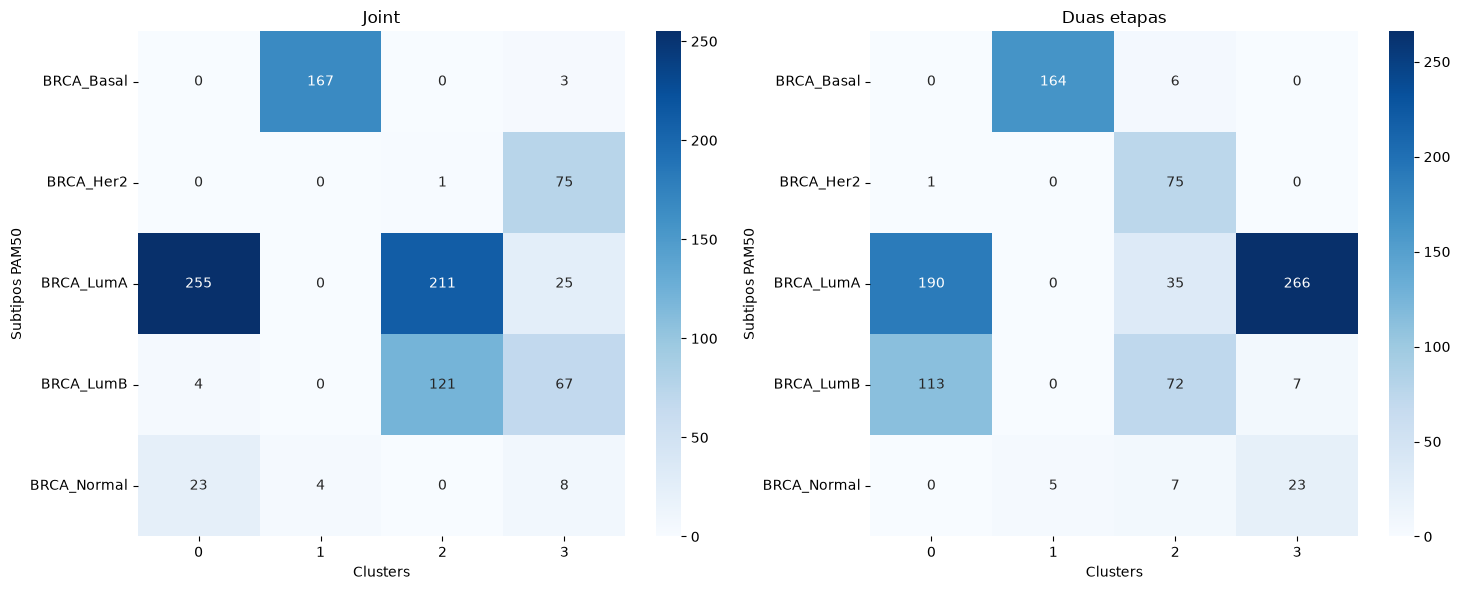

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    contingency_joint,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Joint")
axes[0].set_xlabel("Clusters")
axes[0].set_ylabel("Subtipos PAM50")

sns.heatmap(
    contingency_decoupled,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)

axes[1].set_title("Duas etapas")
axes[1].set_xlabel("Clusters")
axes[1].set_ylabel("Subtipos PAM50")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "contingency_vst_mad_5000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Plot dos Embeddings

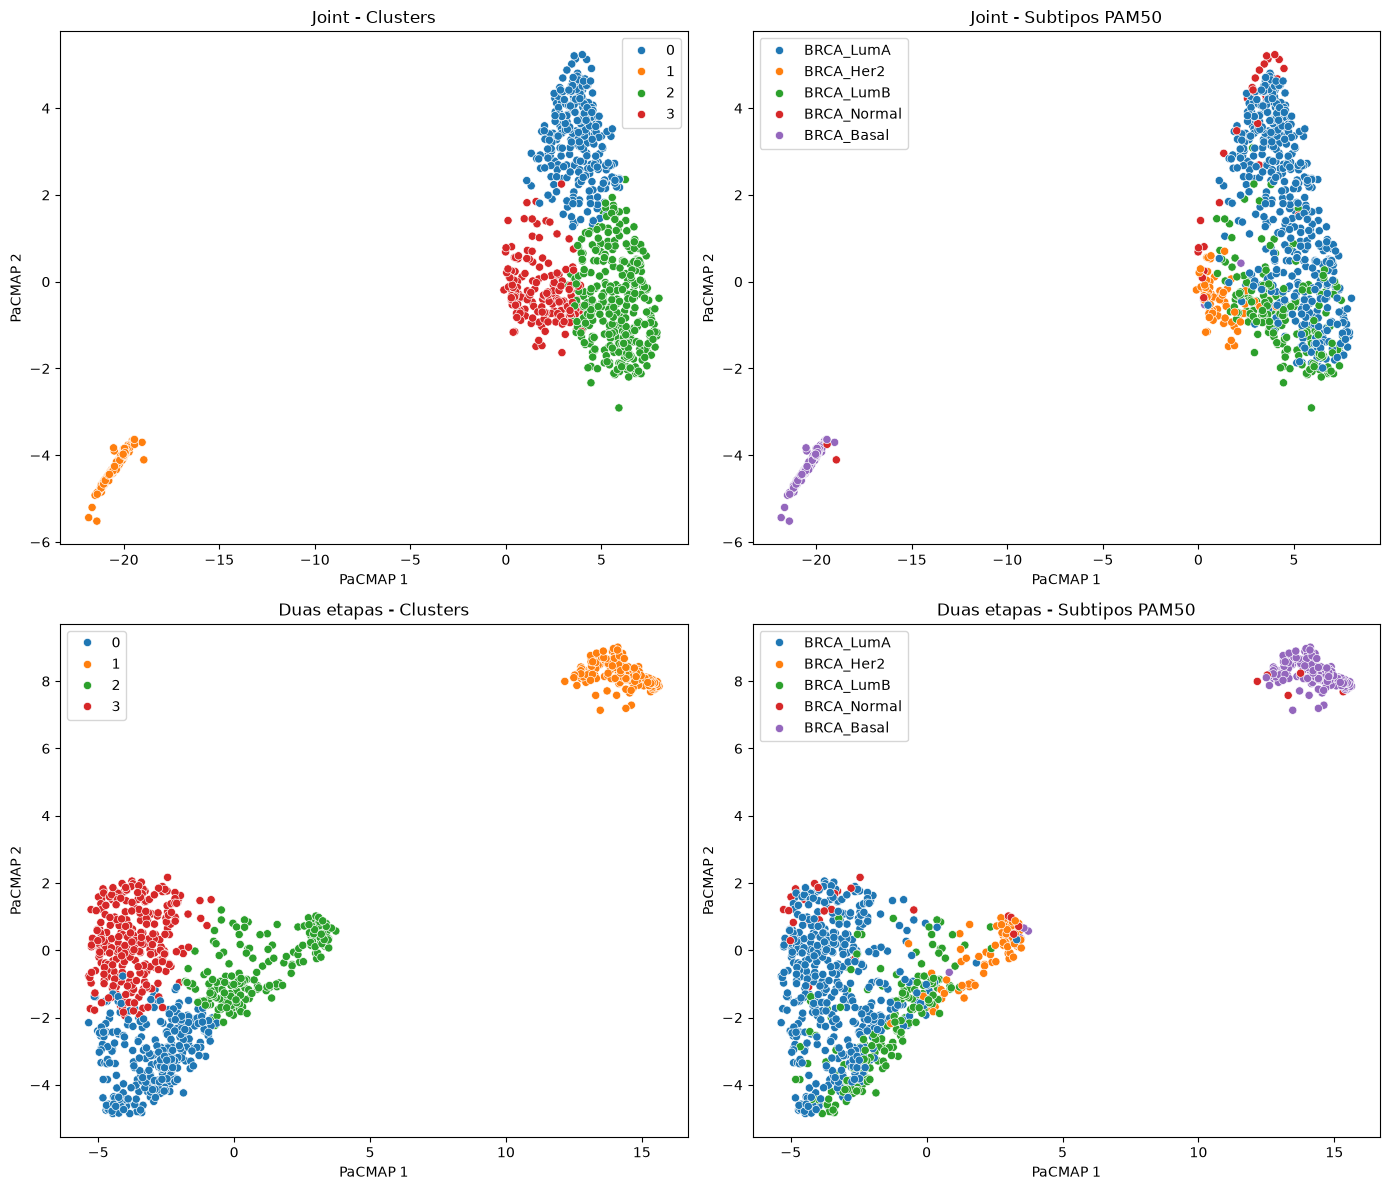

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Joint - clusters
sns.scatterplot(
    x=Z_joint[:, 0],
    y=Z_joint[:, 1],
    hue=labels_joint,
    palette="tab10",
    s=35,
    ax=axes[0, 0],
    legend="full"
)

axes[0, 0].set_title("Joint - Clusters")
axes[0, 0].set_xlabel("PaCMAP 1")
axes[0, 0].set_ylabel("PaCMAP 2")

# Joint - subtipos
sns.scatterplot(
    x=Z_joint[:, 0],
    y=Z_joint[:, 1],
    hue=y_true,
    palette="tab10",
    s=35,
    ax=axes[0, 1],
    legend="full"
)

axes[0, 1].set_title("Joint - Subtipos PAM50")
axes[0, 1].set_xlabel("PaCMAP 1")
axes[0, 1].set_ylabel("PaCMAP 2")

# Duas etapas - clusters
sns.scatterplot(
    x=Z_decoupled[:, 0],
    y=Z_decoupled[:, 1],
    hue=labels_decoupled,
    palette="tab10",
    s=35,
    ax=axes[1, 0],
    legend="full"
)

axes[1, 0].set_title("Duas etapas - Clusters")
axes[1, 0].set_xlabel("PaCMAP 1")
axes[1, 0].set_ylabel("PaCMAP 2")

# Duas etapas - subtipos
sns.scatterplot(
    x=Z_decoupled[:, 0],
    y=Z_decoupled[:, 1],
    hue=y_true,
    palette="tab10",
    s=35,
    ax=axes[1, 1],
    legend="full"
)

axes[1, 1].set_title("Duas etapas - Subtipos PAM50")
axes[1, 1].set_xlabel("PaCMAP 1")
axes[1, 1].set_ylabel("PaCMAP 2")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "embeddings_vst_mad_5000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Comparação das Métricas

In [26]:
results_comparison = pd.DataFrame({
    "Estratégia": [
        "Joint",
        "Duas etapas"
    ],

    "Qlocal": [
        best_trial_joint.user_attrs["Qlocal"],
        q_local_decoupled
    ],

    "AUC QNN": [
        best_trial_joint.user_attrs["AUC_QNN"],
        auc_qnn_decoupled
    ],

    "Silhouette": [
        best_trial_joint.user_attrs["Silhouette"],
        sil_decoupled
    ],

    "Calinski-Harabasz": [
        best_trial_joint.user_attrs["Calinski_Harabasz"],
        ch_decoupled
    ],

    "ARI": [
        adjusted_rand_score(y_true, labels_joint),
        ari_decoupled
    ],

    "Número de clusters": [
        len(np.unique(labels_joint)),
        len(np.unique(labels_decoupled))
    ]
})

display(results_comparison.round(4))

results_comparison.to_csv(
    METRICS_DIR / "comparison_vst_mad_5000.csv",
    index=False
)

,Estratégia,Qlocal,AUC QNN,Silhouette,Calinski-Harabasz,ARI,Número de clusters
0,Joint,0.4736,0.7752,0.5486,13461.4699,0.3960,4
1,Duas etapas,0.4967,0.7744,0.5174,4987.2372,0.3842,4


## Comparação dos parâmetros

In [28]:
import json
import pandas as pd

# ============================================================
# CARREGAMENTO DOS HIPERPARÂMETROS DOS BEST TRIALS
# ============================================================

# 1. Recupera parâmetros da Abordagem Joint
if 'best_trial_joint' in locals() and hasattr(best_trial_joint, 'params'):
    best_params_joint = best_trial_joint.params
else:
    json_joint_file = OPTUNA_DIR / "best_params_joint_vst_mad_5000.json"
    if not json_joint_file.exists():
        json_joint_file = OPTUNA_DIR / "best_trial_info_mad_5000.json"
        with open(json_joint_file, "r") as f:
            best_params_joint = json.load(f)["params"]
    else:
        with open(json_joint_file, "r") as f:
            best_params_joint = json.load(f)

# 2. Recupera parâmetros do PaCMAP (Duas Etapas)
if 'best_params_pacmap' not in locals():
    json_pacmap_file = OPTUNA_DIR / "best_params_pacmap_vst_mad_5000.json"
    if not json_pacmap_file.exists():
        json_decoupled_file = OPTUNA_DIR / "best_trial_info_decoupled_vst_mad_5000.json"
        with open(json_decoupled_file, "r") as f:
            best_params_pacmap = json.load(f)["pacmap_optimization"]["params"]
    else:
        with open(json_pacmap_file, "r") as f:
            best_params_pacmap = json.load(f)

# 3. Recupera parâmetros do GMM (Duas Etapas)
if 'best_params_gmm' not in locals():
    json_gmm_file = OPTUNA_DIR / "best_params_gmm_vst_mad_5000.json"
    if not json_gmm_file.exists():
        json_decoupled_file = OPTUNA_DIR / "best_trial_info_decoupled_vst_mad_5000.json"
        with open(json_decoupled_file, "r") as f:
            best_params_gmm = json.load(f)["gmm_optimization"]["params"]
    else:
        with open(json_gmm_file, "r") as f:
            best_params_gmm = json.load(f)

# ============================================================
# CONSTRUÇÃO E SALVAMENTO DO DATAFRAME
# ============================================================

params_comparison = pd.DataFrame([
    {
        "Estratégia": "Joint",
        **best_params_joint
    },
    {
        "Estratégia": "Duas etapas",
        **{
            "n_neighbors": best_params_pacmap.get("n_neighbors"),
            "MN_ratio": best_params_pacmap.get("MN_ratio"),
            "FP_ratio": best_params_pacmap.get("FP_ratio"),
            "n_components": best_params_pacmap.get("n_components", 2),
            "gmm_n_components": best_params_gmm.get("n_components", 5),
            "covariance_type": best_params_gmm.get("covariance_type"),
            "n_init": best_params_gmm.get("n_init", 1)
        }
    }
])

display(params_comparison)

params_comparison.to_csv(
    METRICS_DIR / "hyperparameters_vst_mad_5000.csv",
    index=False
)

,Estratégia,n_neighbors,MN_ratio,FP_ratio,n_components,gmm_n_components,covariance_type,n_init
0,Joint,117,0.117205,2.936949,7,4,tied,15
1,Duas etapas,22,2.689803,2.927995,9,4,spherical,13
